In [1]:
from utils.config import GOALS
from utils.simulations import generate_cases

cases_df = generate_cases(GOALS, num_samples_per_goal=500)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df

,goal,tp,wd,ds,zs
0,1,12.213669,41.475232,18.939314,1.302719
1,1,8.383269,41.711663,13.775162,-2.609729
2,1,6.444611,3.513780,13.077691,0.370466
3,1,5.190768,301.394214,42.685319,3.339651
4,1,7.184247,100.201556,21.310096,2.068328
...,...,...,...,...,...
6995,14,3.085851,114.008059,6.058686,1.661343
6996,14,5.567329,71.343141,26.999642,1.527603
6997,14,10.803596,228.367410,8.893153,-2.413709
6998,14,5.626369,61.880209,38.968768,-0.523276


<Axes: xlabel='tp', ylabel='wd'>

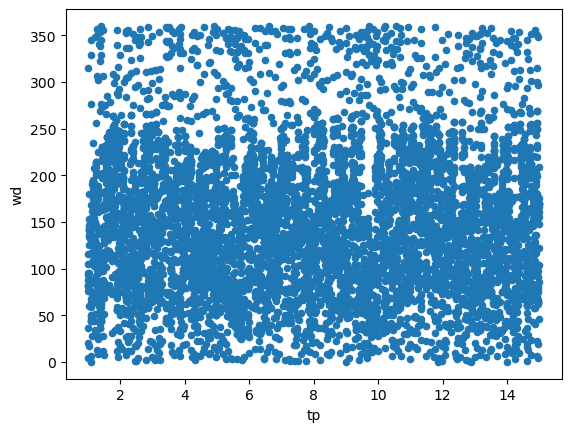

In [2]:
cases_df.plot.scatter(x="tp", y="wd")

In [3]:
from utils.snapwave_wrapper import SnapWaveMetaModelWrapper

# Auto-loads the `output_sites` config: `build_case` drops `output_sites.txt`
# into each case dir, and `postprocess_case` relabels SnapWave stations as
# `10m_0`, `20m_65`, `buoy_41013`, ... using the in-memory `output_sites_df`.
snapwave_wrapper = SnapWaveMetaModelWrapper(
    templates_dir="templates-metamodel",
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={},
    output_dir="SnapWave_CASES_Metamodel",
    aoi_file="inputs/AoI_Polygons/AoI_NorthCarolina.shp",
    goals_config=GOALS,
)
snapwave_wrapper

2026-06-16 22:56:46,368 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-06-16 22:56:46,368 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-06-16 22:56:46,368 - SnapWaveMetaModelWrapper - WARNING - Parameter wd is not in the default_parameters
2026-06-16 22:56:46,369 - SnapWaveMetaModelWrapper - WARNING - Parameter ds is not in the default_parameters
2026-06-16 22:56:46,369 - SnapWaveMetaModelWrapper - WARNING - Parameter zs is not in the default_parameters


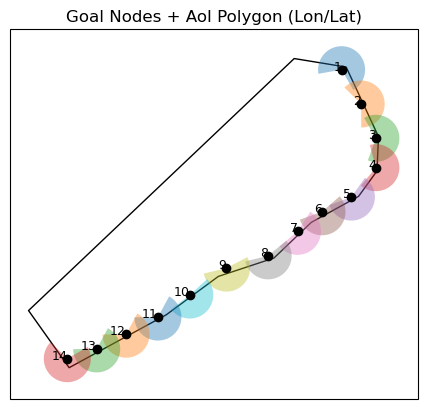

In [4]:
snapwave_wrapper.plot_configuration()

In [6]:
snapwave_wrapper.output_sites_df.to_csv("output_sites.csv")

In [8]:
snapwave_wrapper.load_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [ ]:
# snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [9]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    7000
Name: count, dtype: int64

In [10]:
msg = snapwave_wrapper.postprocess_cases()
msg

'Olrait!'